Registered users | Working days: peak 17:00, 468.4 rentals/hour
Registered users | Days off / holidays: peak 12:00, 240.0 rentals/hour
Casual users | Working days: peak 17:00, 56.9 rentals/hour
Casual users | Days off / holidays: peak 14:00, 139.6 rentals/hour


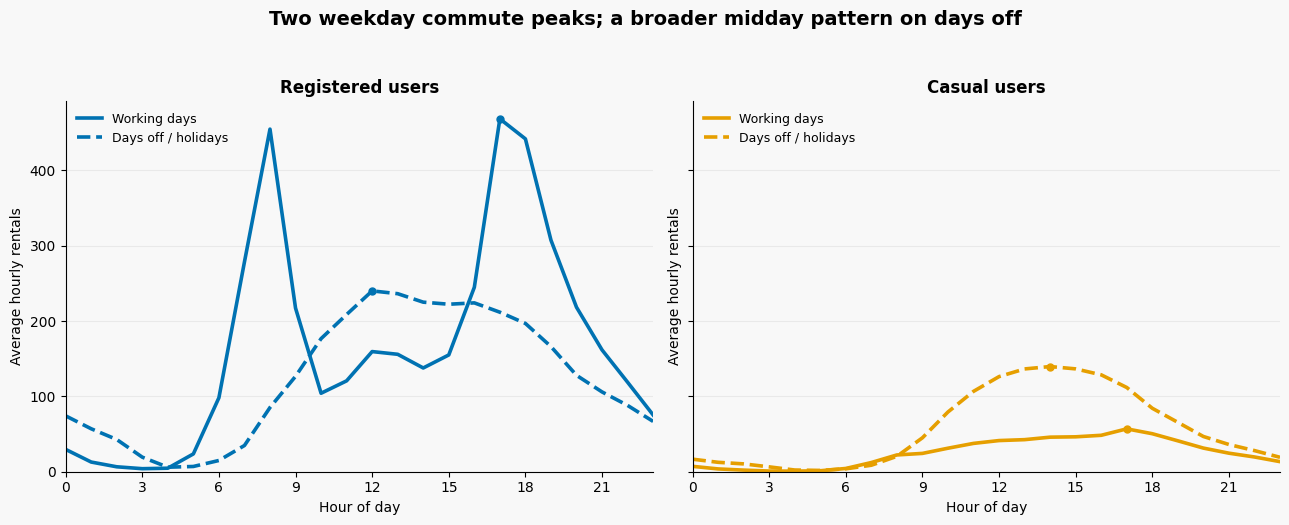

In [1]:
# Orari di utilizzo e settimana

# Carichiamo le librerie e impostiamo i colori dei grafici.
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

MUTED = '#647280'
REGISTERED = '#0072B2'
CASUAL = '#E69F00'
DARK = '#253342'
SEQUENTIAL_CMAP = 'cividis'
plt.rcParams['figure.facecolor'] = '#F8F8F8'
plt.rcParams['axes.facecolor'] = '#F8F8F8'
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False

# Apriamo i dati orari già puliti e prepariamo la cartella dei grafici.
hour = pd.read_csv('../data/processed/bike_hour_clean.csv')
if 'day_name' not in hour.columns:
    hour['day_name'] = pd.to_datetime(hour['dteday']).dt.day_name()
Path('../output/figures').mkdir(parents=True, exist_ok=True)

# Usiamo sempre blu per i registrati e arancione per gli occasionali.
COLORS = {'registered': REGISTERED, 'casual': CASUAL}

# Calcoliamo i noleggi medi per ora e tipo di giornata.
hourly_avg = hour.groupby(['workingday','hr'])[['registered','casual']].mean().reset_index()

# Disegniamo due pannelli con la stessa scala per confrontare gli utenti.
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)

# Tracciamo le curve e individuiamo le ore di punta.
for ax, key, label in zip(axes, ['registered','casual'], ['Registered users','Casual users']):
    color = COLORS[key]
    for workingday, line_style, day_label in [(1,'-','Working days'), (0,'--','Days off / holidays')]:
        part = hourly_avg[hourly_avg['workingday']==workingday]
        ax.plot(part['hr'],part[key],linestyle=line_style, linewidth=2.6,
                color=color,label=day_label)
        pk = part.loc[part[key].idxmax()]
        ax.scatter([pk['hr']],[pk[key]],color=color,s=25,zorder=4)
        print(f'{label} | {day_label}: peak {int(pk["hr"]):02d}:00, '
              f'{pk[key]:.1f} rentals/hour')
    ax.set_title(label,fontweight='bold')
    ax.set_xlabel('Hour of day')
    ax.set_ylabel('Average hourly rentals')
    ax.set_xticks(range(0,24,3))
    ax.set_xlim(0,23)
    ax.set_ylim(bottom=0)
    ax.grid(axis='y', alpha=0.2); ax.set_axisbelow(True)
    ax.legend(frameon=False,loc='upper left', fontsize=9)

# Aggiungiamo un titolo e salviamo il grafico.
fig.suptitle('Two weekday commute peaks; a broader midday pattern on days off',
             fontsize=14,fontweight='bold',y=1.04)
fig.tight_layout()
fig.savefig('../output/figures/RQ1_daily_rhythm.png',dpi=200,bbox_inches='tight')
plt.show()

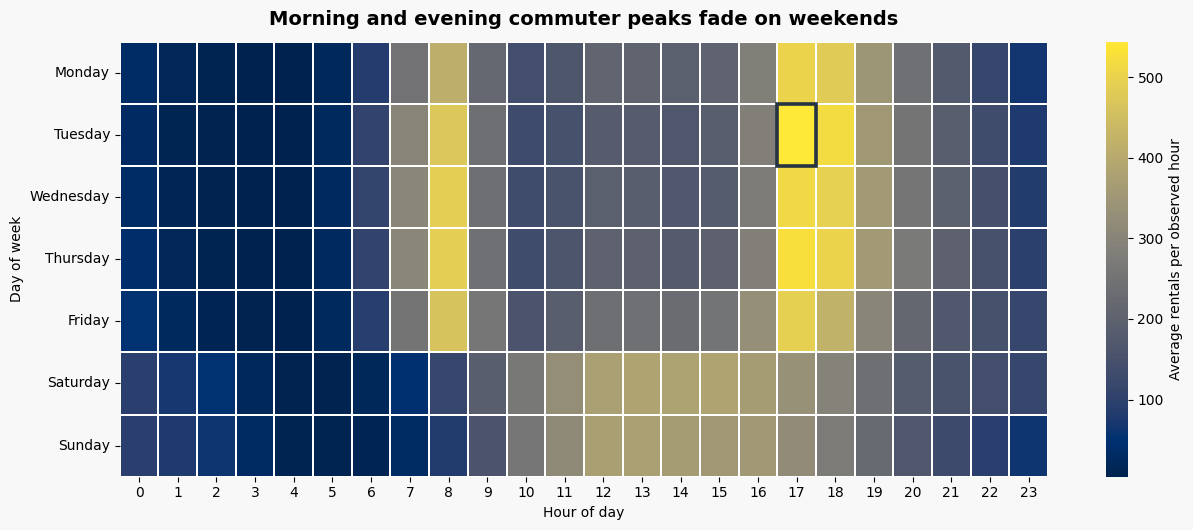

Weekly mean peak: Tuesday at 17:00, 544.3 rentals/hour.


In [2]:
# Definiamo l’ordine corretto dei giorni della settimana.
days = ['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']

# Calcoliamo i noleggi medi per ciascun giorno e ora.
weekly = (hour.groupby(['day_name','hr'])['cnt'].mean().unstack()
          .reindex(index=days, columns=range(24)))

# Troviamo giorno e ora con la media più alta.
peak_day,peak_hour = weekly.stack().idxmax()
peak_value = weekly.stack().max()

# Creiamo la heatmap con scala cromatica e legenda.
fig,ax=plt.subplots(figsize=(13,5.4))
sns.heatmap(weekly,cmap=SEQUENTIAL_CMAP,linewidths=.3,ax=ax,
            cbar_kws={'label':'Average rentals per observed hour'})
ax.set_title('Morning and evening commuter peaks fade on weekends',
             fontsize=14,fontweight='bold',pad=12)
ax.set_xlabel('Hour of day');ax.set_ylabel('Day of week')
ax.tick_params(axis='x',rotation=0);ax.tick_params(axis='y',rotation=0)

# Evidenziamo la cella con il picco massimo.
ax.add_patch(plt.Rectangle((peak_hour,days.index(peak_day)),1,1,fill=False,
                           edgecolor=DARK,linewidth=2.6))

# Salviamo la figura.
fig.tight_layout()
fig.savefig('../output/figures/RQ2_weekly_heatmap.png',dpi=200,bbox_inches='tight')
plt.show()
print(f'Weekly mean peak: {peak_day} at {peak_hour:02d}:00, {peak_value:.1f} rentals/hour.')